In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
import seaborn as sns
from kneed import KneeLocator
from sklearn.metrics import silhouette_score

In [4]:
df = pd.read_csv("smartcart_customers.csv")
df.head(4)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0


In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing

## 1. Handle Missing Values

In [7]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [21]:
df.head(10)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Customer_Tenure_Days,Total_spending,Total_children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1
5,7446,1967,Master,Together,62513.0,0,1,2013-09-09,16,520,...,6,4,10,6,0,0,59,293,716,1
6,965,1971,Graduation,Divorced,55635.0,0,1,2012-11-13,34,235,...,7,3,7,6,0,0,55,593,590,1
7,6177,1985,PhD,Married,33454.0,1,0,2013-05-08,32,76,...,4,0,4,8,0,0,41,417,169,1
8,4855,1974,PhD,Together,30351.0,1,0,2013-06-06,19,14,...,3,0,2,9,0,1,52,388,46,1
9,5899,1950,PhD,Together,5648.0,1,1,2014-03-13,68,28,...,1,0,0,20,0,0,76,108,49,2


## Feature engineering

In [9]:
#age
df["age"] = 2026 - df["Year_Birth"]

In [14]:
# Customer Joining Date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)
reference_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

In [15]:
# spending
df["Total_spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"]  + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [16]:
# total_children
df["Total_children"] = df["Kidhome"] + df["Teenhome"]

In [22]:
# Education
df["Education"].value_counts()
df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate",
    "Graduation" : "Graduate",
    "2n Cycle" : "Undergraduate",
    "Master" : "Postgraduate", "PhD" : "Postgraduate"
})

In [24]:
# Marital status
df["Marital_Status"].value_counts()
df["Living_With"] = df["Marital_Status"].replace({
    "Married" : "Partner",
    "Together" : "Partner",
    "Single" :  "Alone",
    "Divorced" : "Alone",
    "Widow"   : "Alone",
    "Alone"    : "Alone",
    "Absurd"   : "Alone",
    "YOLO"     : "Alone"
})

## Drop Columns

In [28]:
cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

col_to_drop = cols + spending_cols
df_cleaned = df.drop(col_to_drop, axis =1)

In [29]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Customer_Tenure_Days,Total_spending,Total_children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# Outliers

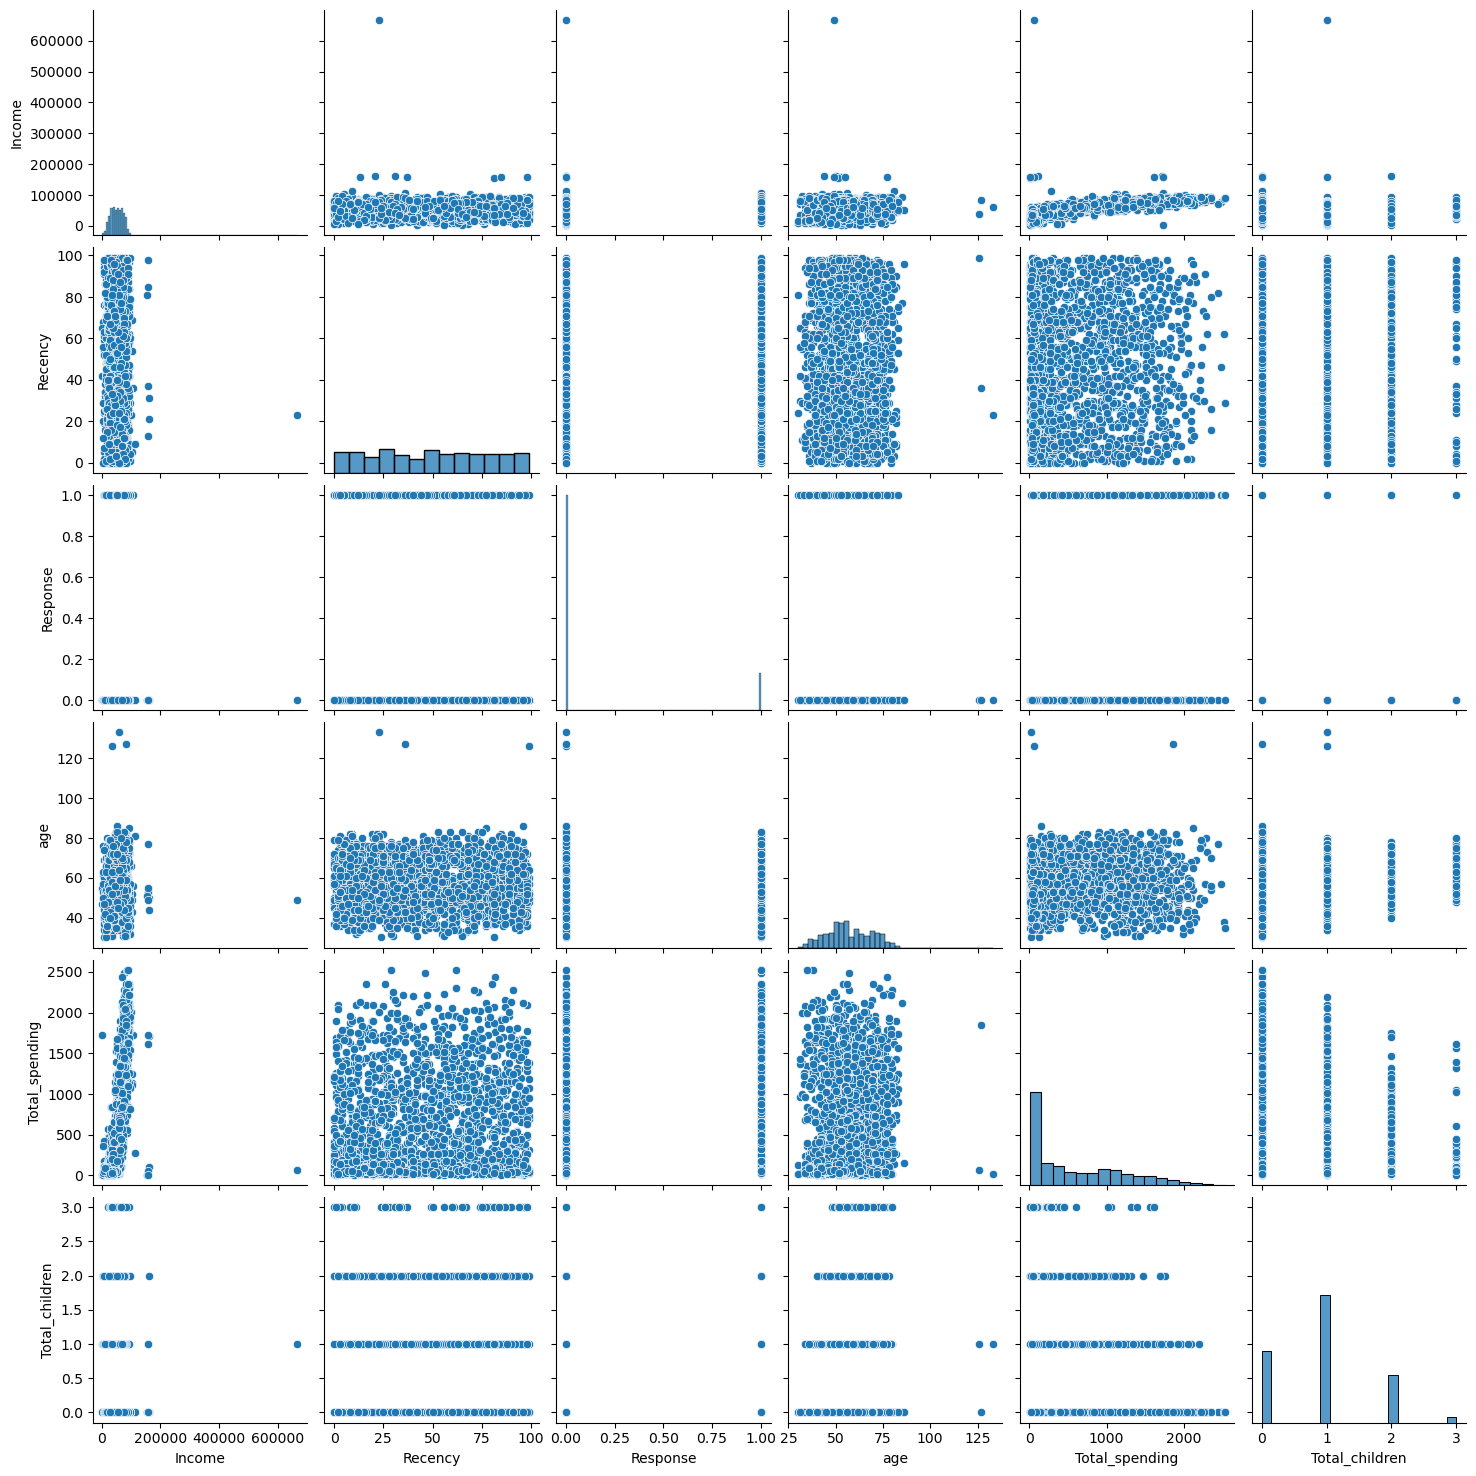

In [32]:
cols = ["Income", "Recency", "Response", "age", "Total_spending", "Total_children"]

sns.pairplot(df_cleaned[cols])

In [37]:
# Remove outliers

print("data size with outliner:", len(df_cleaned))

df_cleaned = df_cleaned[( df_cleaned["Income"] < 600000) ]
df_cleaned = df_cleaned[df_cleaned["age"] < 90]

print("data size after removing outliner:", len(df_cleaned))

data size with outliner: 2240
data size after removing outliner: 2236


# Heatmap

In [38]:
corr = df_cleaned.corr(numeric_only = True)

<Axes: >

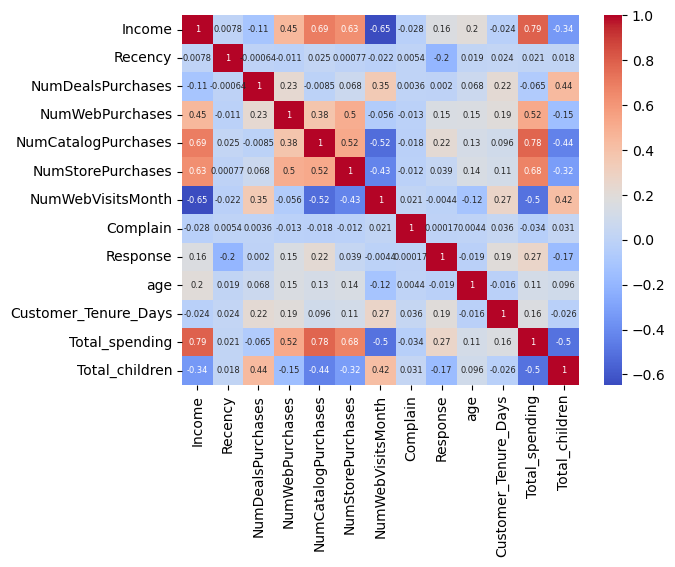

In [40]:
sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size" : 6},
    cmap = "coolwarm"
)

# Encoding

In [42]:
ohe = OneHotEncoder()
cat_cols = ["Education", "Living_With"]
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])


In [45]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns = ohe.get_feature_names_out(cat_cols), index= df_cleaned.index)

In [47]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols), enc_df], axis = 1)

In [48]:
df_encoded.shape

(2236, 18)

# Scaling

In [97]:
x = df_encoded
ss = StandardScaler()
x_scaled = ss.fit_transform(df_encoded)

# Visualize

In [53]:
pca = PCA(n_components = 3)
x_pca = pca.fit_transform(x_scaled)

In [52]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

Text(0.5, 0.92, '3d projection')

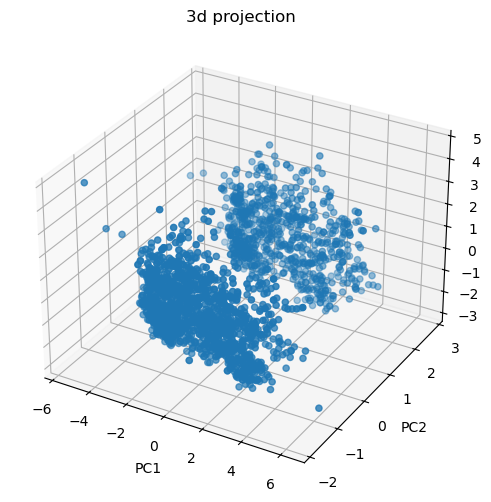

In [58]:
# plot
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3d projection")

# Analyze K value
## 1. Elbow Method

In [71]:
wcss = []
for i in range(1,11):
    kmeans = KMeans(n_clusters = i, random_state=42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)

In [72]:
knee = KneeLocator(range(1,11), wcss,curve="convex", direction="decreasing")
optimal = knee.elbow

In [73]:
print("best knee:", optimal)

best knee: 4


Text(0, 0.5, 'WCSS')

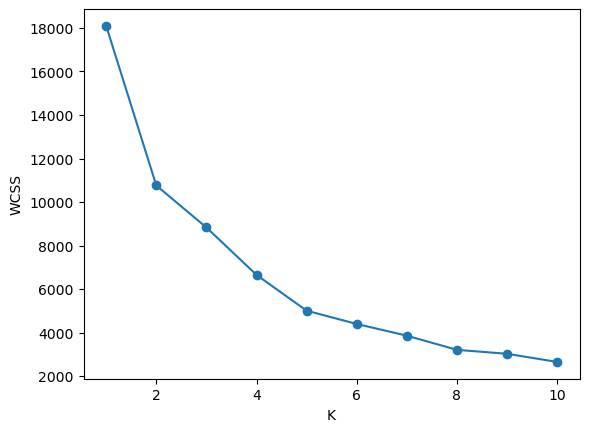

In [74]:
plt.plot(range(1,11), wcss, marker = 'o')
plt.xlabel("K")
plt.ylabel("WCSS")

## 2. Silhouette Score

In [69]:
ss = []
for i in range(2,11):
    kmeans = KMeans(n_clusters = i, random_state=42)
    labels = kmeans.fit_predict(x_pca)
    score = silhouette_score(x_pca,labels)
    ss.append(score)

Text(0, 0.5, 'SS')

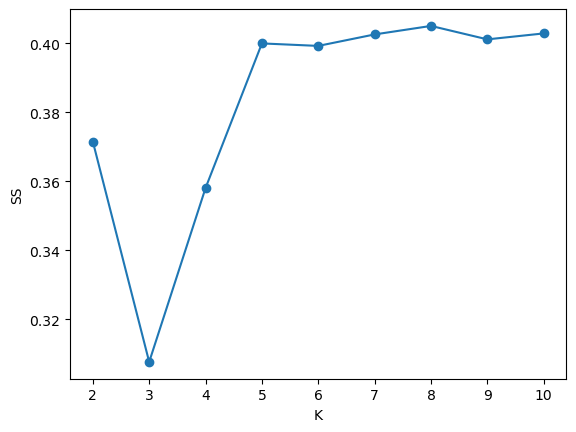

In [70]:
plt.plot(range(2,11), ss, marker = 'o')
plt.xlabel("K")
plt.ylabel("SS")

Text(0, 0.5, 'ss')

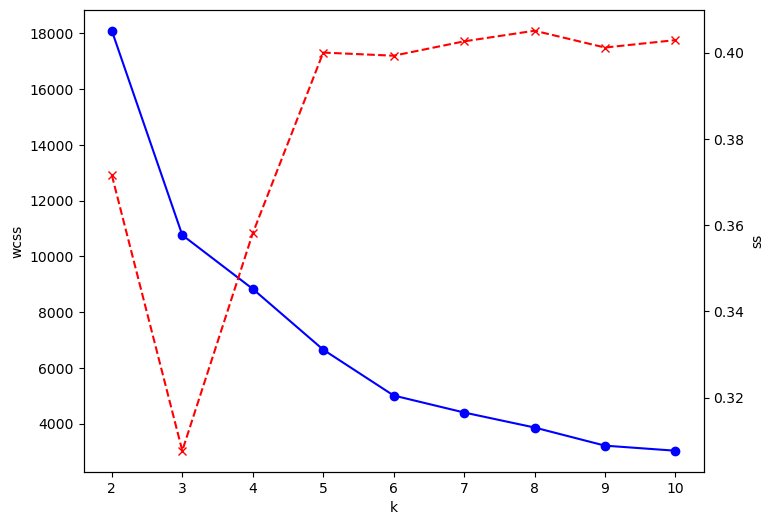

In [79]:
# combined plot
k = range(2,11)
fig, ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k, wcss[:len(k)], marker = 'o', color = "blue")
ax1.set_xlabel("k")
ax1.set_ylabel("wcss")

ax2 = ax1.twinx()
ax2.plot(k, ss[:len(k)], marker = 'x', color = "red", linestyle = '--')
ax2.set_ylabel("ss")

# Clustering

In [80]:
kmeans = KMeans(n_clusters = 4, random_state = 42)
label = kmeans.fit_predict(x_pca)

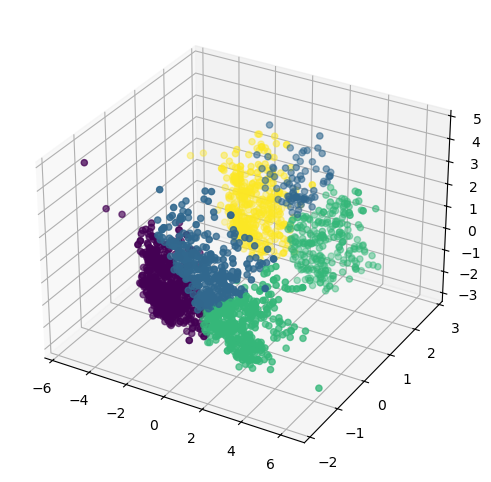

In [88]:
fig = plt.figure(figsize =(8,6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2], c = label) 

In [91]:
# Agglomerative clustering
agg = AgglomerativeClustering(n_clusters = 4, linkage = "ward")
label_agg = agg.fit_predict(x_pca)

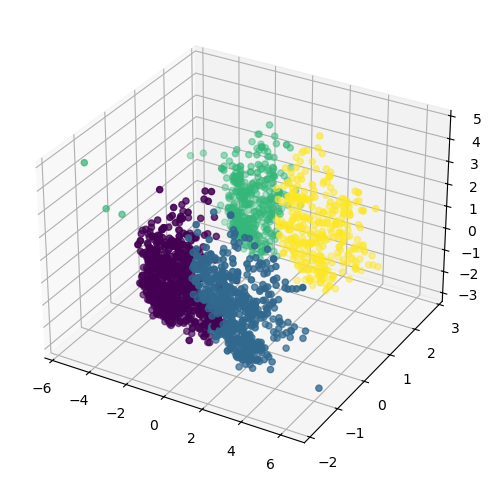

In [92]:
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(x_pca[:,0], x_pca[:,1], x_pca[:,2], c= label_agg)

# Characterization of Clusters

In [98]:
x["clusters"] = label_agg

In [99]:
x.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Customer_Tenure_Days,Total_spending,Total_children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='clusters', ylabel='count'>

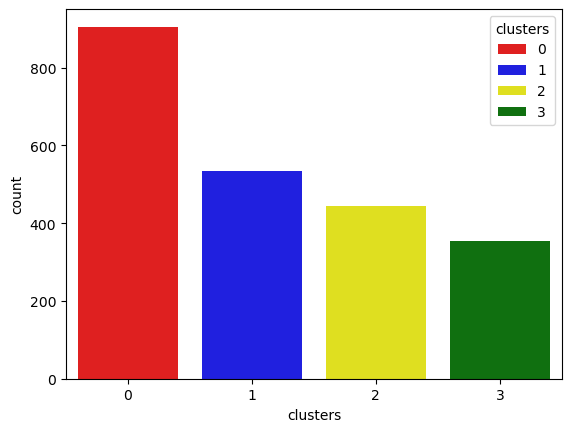

In [102]:
pal = ["red", "blue", "yellow", "green"]
sns.countplot(x= x["clusters"], palette = pal, hue = x["clusters"])

In [104]:
x.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Customer_Tenure_Days,Total_spending,Total_children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='Total_spending', ylabel='Income'>

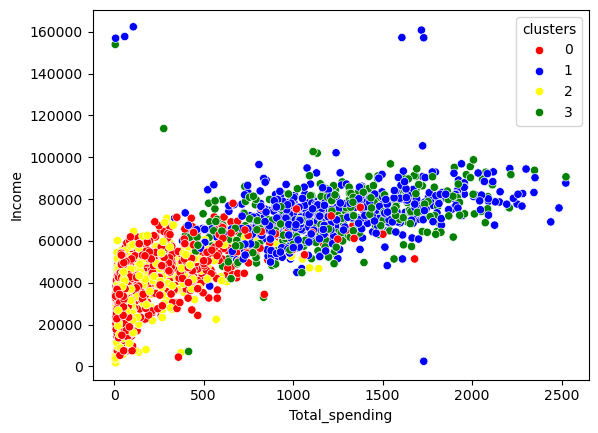

In [105]:
# Income & Spending patterns

sns.scatterplot(x=x["Total_spending"], y=x["Income"], hue=x["clusters"], palette=pal)

In [108]:
# cluster summary
cluster_summary = x.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         39680.580110  48.914917           2.594475         3.153591   
1         72808.445693  49.202247           1.958801         5.687266   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.969061           4.143646           6.307182  0.011050   
1                    5.498127           8.659176           3.580524  0.005618   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        age  Customer_Tenure_Days  Total_spending  \
clu